<div >
  <div font-weight:700;">СИСТЕМЫ ИСКУССТВЕННОГО ИНТЕЛЛЕКТА И МАШИННОЕ ОБУЧЕНИЕ</div>
  <h1  ">Лабораторная работа № 2</h1>
  <h2   font-weight:500;">Классификация данных и нейронные сети</h2>
  <p  ">Наивный Байес · Decision Tree · LDA · SVM · kNN · SMOTE · TensorFlow · TensorBoard</p>
</div>

**Датасет:** Red Wine Quality — `winequality-red.csv`  
**Целевая переменная:** `quality` — шесть исходных классов {3, 4, 5, 6, 7, 8}  
**Цель:** построить и сравнить классификаторы, исследовать дисбаланс классов, гиперпараметры и нейронную сеть.

> **Что изменено после замечаний преподавателя:** добавлено сравнение **без SMOTE / со SMOTE**; после каждого логического участка кода приводится **результат (таблица или график), затем пояснение и вывод**. Балансировка выполняется **только внутри обучения**, без изменения тестовых данных.

---

## Навигация по работе

| Раздел | Содержание |
|---|---|
| **01. Исходные данные** | загрузка, пропуски, дубликаты, распределение классов |
| **02. Предобработка и SMOTE** | стратифицированное разделение, демонстрация балансировки |
| **03. Классификаторы** | 4 варианта NB, дерево, LDA, SVM, kNN |
| **04. Гиперпараметры** | GridSearchCV + StratifiedKFold + защита от утечек |
| **05. Метрики** | Accuracy, Precision, Recall, F1, ROC-AUC, сравнение с SMOTE |
| **06. Ошибки и ROC** | confusion matrix, отчёт по каждому классу, ROC OvR |
| **07. Анализ гиперпараметров** | дерево: глубина и переобучение |
| **08. TensorFlow** | архитектуры MLP, влияние SMOTE, EarlyStopping, TensorBoard |
| **09. Выводы** | итоговое сравнение, ограничения, вопросы к защите |

**Порядок запуска:** последовательно «Run all» (Kernel → Restart & Run All). Для работы нужен CSV в той же папке. Для блока TensorFlow требуется дополнительная установка, указанная далее.

## 00. Подготовка окружения

Если каких-то библиотек нет, выполните **один раз** в отдельной ячейке Jupyter (без `#`):

```python
%pip install -U pandas numpy matplotlib seaborn scikit-learn imbalanced-learn ipython
%pip install tensorflow tensorboard
```

После установки перезапустите ядро Jupyter. TensorFlow может потребовать совместимую версию Python. Зависимости отдельно перечислены в `requirements.txt`.

Ниже код проверяет наличие TensorFlow: если он не установлен, основной раздел scikit-learn продолжает работать, а нейросетевой блок выдаёт понятное сообщение вместо падения ноутбука.

In [24]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.base import clone
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline  # НЕ sklearn.pipeline.Pipeline: sampler применяем при fit

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 105, "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.family": "DejaVu Sans"})

print("✓ Импорты успешны; seed =", SEED)
print("Scikit-Learn:", __import__("sklearn").__version__)
print("Imbalanced-Learn:", __import__("imblearn").__version__)

✓ Импорты успешны; seed = 42
Scikit-Learn: 1.9.1
Imbalanced-Learn: 0.14.2


**Пояснение.** В данном исследовании используется `imblearn.pipeline.Pipeline`, потому что обычный `sklearn.pipeline.Pipeline` не умеет корректно включать шаг ресемплинга SMOTE. Выбранное начальное значение `SEED=42` повышает воспроизводимость экспериментов, хотя отдельные вычисления могут немного отличаться на разных версиях библиотек.

## 01. Загрузка и первичный анализ данных

**Постановка:** каждый объект — образец вина, признаки — 11 числовых физико-химических измерений, `quality` — экспертная целочисленная оценка от 3 до 8. В этой работе оценки рассматриваются как **шесть классов** (в отличие от лабораторной №1, где решалась регрессия).

In [25]:
csv_path = Path("winequality-red.csv")
if not csv_path.exists():
    csv_path = Path("data/winequality-red.csv")
if not csv_path.exists():
    raise FileNotFoundError("Поместите winequality-red.csv рядом с ноутбуком")

df = pd.read_csv(csv_path)
print(f"Размер исходной таблицы: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("Число пропусков:", int(df.isna().sum().sum()))
print("Полных дубликатов:", int(df.duplicated().sum()))
display(df.head(6))
display(df.dtypes.rename("Тип столбца").to_frame())

Размер исходной таблицы: 1599 строк, 12 столбцов
Число пропусков: 0
Полных дубликатов: 240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


,Тип столбца
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


**Описание результата.** В исходной таблице **1599 строк и 12 столбцов**. Из них 11 являются входными количественными признаками, а `quality` — целевой класс. Пропуски отсутствуют, присутствуют **240 полностью совпадающих строк**. Дальше устраним полные дубликаты, чтобы одинаковые записи не оказались одновременно в train и test. При этом нельзя утверждать, что каждый дубль обязательно является ошибкой измерения: это выбранное правило очистки для данной учебной работы.

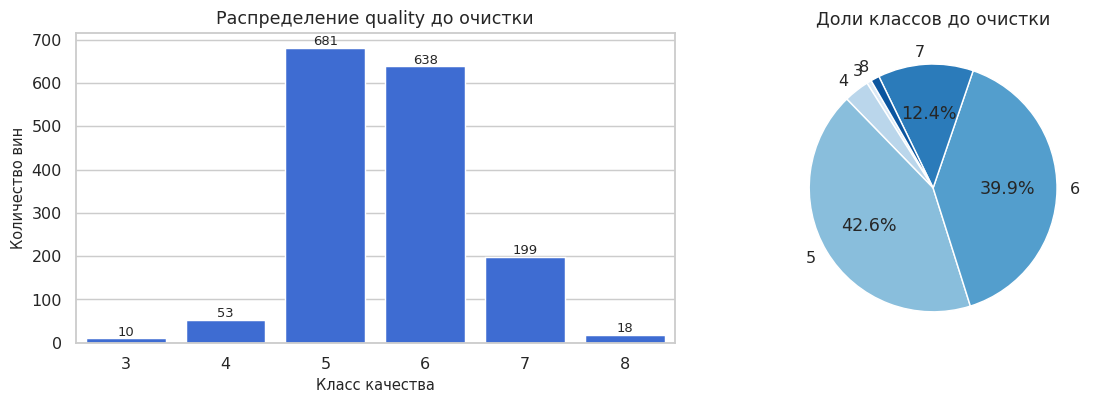

,Количество,"Доля, %"
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


In [26]:
raw_counts = df["quality"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=raw_counts.index.astype(str), y=raw_counts.values, color="#2563eb", ax=axes[0])
axes[0].set(title="Распределение quality до очистки", xlabel="Класс качества", ylabel="Количество вин")
for i, v in enumerate(raw_counts.values): axes[0].text(i, v + 7, str(v), ha="center", fontsize=9)
axes[1].pie(raw_counts.values, labels=[str(k) for k in raw_counts.index],
            autopct=lambda p: f"{p:.1f}%" if p > 4 else "", startangle=120,
            colors=sns.color_palette("Blues", len(raw_counts)))
axes[1].set(title="Доли классов до очистки")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Количество": raw_counts, "Доля, %": (raw_counts/raw_counts.sum()*100).round(2)}))

**Анализ графиков.** В исходном датасете преобладают классы **5 и 6**, тогда как классы **3 и 8 крайне малочисленны**. Поэтому высокая Accuracy сама по себе не гарантирует качественное распознавание редких оценок. Для объективного сравнения понадобится `F1 macro`, который придаёт одинаковый вес каждому классу, а также таблицы Recall по классам.

После очистки: 1359 строк и 11 признаков


,Число образцов,"Доля, %"
quality,,
3,10,0.74
4,53,3.90
5,577,42.46
6,535,39.37
7,167,12.29
8,17,1.25


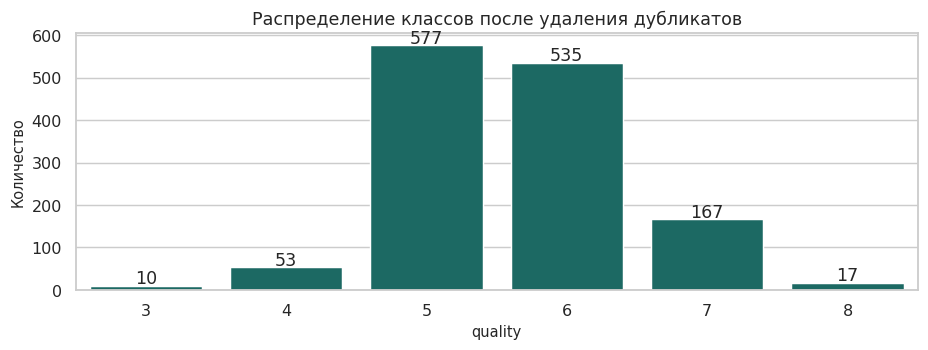

In [27]:
df_clean = df.dropna().drop_duplicates().reset_index(drop=True)
X = df_clean.drop(columns="quality")
y = df_clean["quality"].astype(int)
class_labels = np.sort(y.unique())
clean_counts = y.value_counts().reindex(class_labels)
summary_clean = pd.DataFrame({"Число образцов": clean_counts,
                              "Доля, %": (clean_counts / len(y)*100).round(2)})
print("После очистки:", len(df_clean), "строк и", X.shape[1], "признаков")
display(summary_clean)
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(x=summary_clean.index.astype(str), y=summary_clean["Число образцов"], color="#0f766e", ax=ax)
ax.set(title="Распределение классов после удаления дубликатов", xlabel="quality", ylabel="Количество")
for i, v in enumerate(clean_counts.values): ax.text(i, v+5, str(v), ha="center")
plt.tight_layout(); plt.show()

**Описание результата.** После очистки осталось **1359** объектов. Наиболее многочисленные классы — 5 и 6; класс 3 насчитывает только **10**, класс 8 — **17** образцов. Именно редкие классы являются основной проблемой этой лабораторной. Классы не объединяем: преподавателю будет продемонстрирована полноценная **многоклассовая классификация 3–8**.

## 02. Разделение данных и алгоритм SMOTE

**Критическое правило против утечки:** сначала делим исходные реальные наблюдения на обучающую и тестовую выборки, а **SMOTE применяем исключительно к обучающей части**. Во время `GridSearchCV` SMOTE дополнительно выполняется заново **внутри каждого обучающего fold**. Валидационные и тестовые объекты остаются реальными, без синтетических примеров.

Для контроля распределения классов используется `stratify=y`. При малочисленном классе 3 для SMOTE явно выбираем `k_neighbors=3` вместо стандартных пяти: внутри CV на обучение попадает около 6–7 реальных примеров класса 3.

Train: (1087, 11) Test: (272, 11)


,До деления,Train,Test (НЕ балансируем)
quality,,,
3,10,8,2
4,53,42,11
5,577,461,116
6,535,428,107
7,167,134,33
8,17,14,3


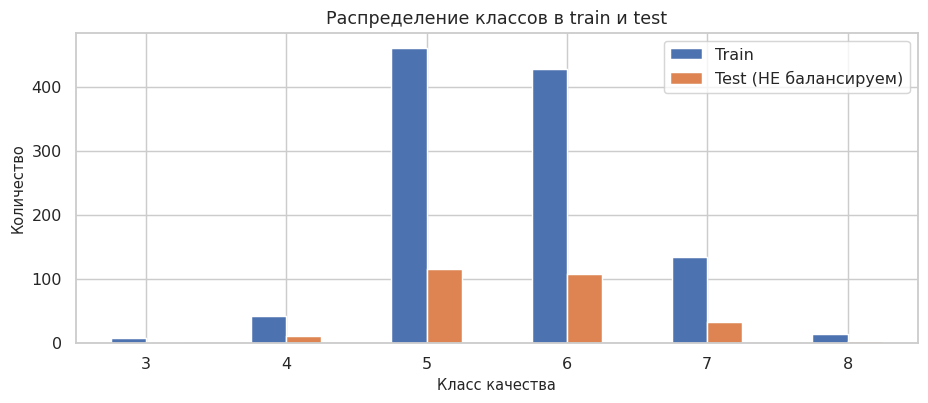

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

split_table = pd.DataFrame({
    "До деления": y.value_counts(),
    "Train": y_train.value_counts(),
    "Test (НЕ балансируем)": y_test.value_counts()
}).sort_index().fillna(0).astype(int)
print("Train:", X_train.shape, "Test:", X_test.shape)
display(split_table)
ax = split_table[["Train", "Test (НЕ балансируем)"]].plot(kind="bar", figsize=(9, 4), rot=0,
                                            title="Распределение классов в train и test")
ax.set(xlabel="Класс качества", ylabel="Количество")
plt.tight_layout(); plt.show()

**Описание результата.** В обучающей выборке **1087**, в тестовой **272** объекта. Доля каждого класса в обеих выборках приблизительно соответствует исходной. Отложенный test не участвует ни в SMOTE, ни в стандартизации, ни в подборе параметров. Это позволяет сравнивать модели в условиях, близких к реальному распределению данных.

### 02.1. Как работает SMOTE

**SMOTE — Synthetic Minority Over-sampling Technique**: для малочисленных классов создаются синтетические точки между реальными объектами одного класса и их ближайшими соседями.

Формула синтетического объекта:

\[
\mathbf{x}_{new}=\mathbf{x}_i+\lambda(\mathbf{x}_{neighbor}-\mathbf{x}_i),\qquad \lambda\in[0,1].
\]
![alt text](image.png)

Это **не копирование строк**, а интерполяция. В данной работе признаки числовые, поэтому классический SMOTE применим. Для удобства расстояний предварительно стандартизируем признаки только на train. Следующая ячейка показывает эффект SMOTE **для иллюстрации**; в моделях дальше SMOTE будет заново запускаться **внутри каждого Pipeline**, а не использовать результат этой демонстрации.

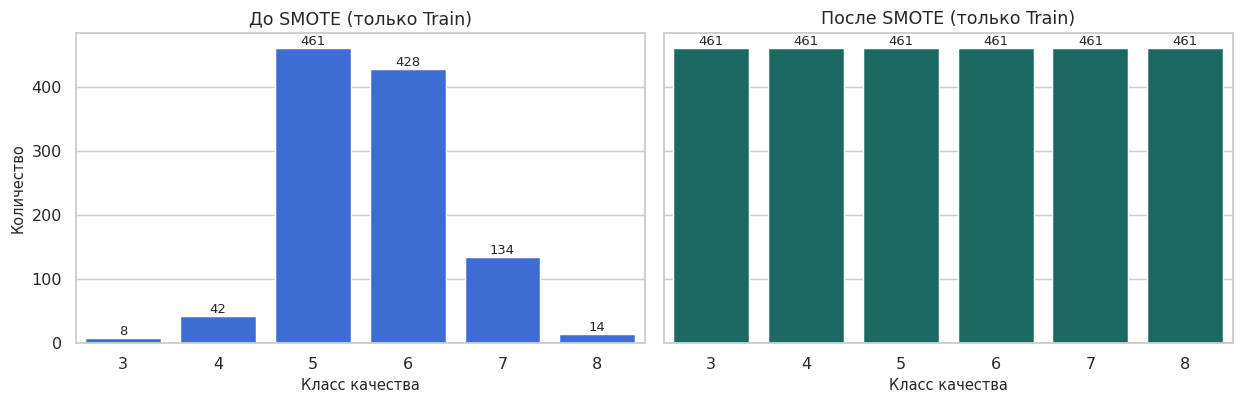

,Реальный Train,Train после SMOTE
quality,,
3,8,461
4,42,461
5,461,461
6,428,461
7,134,461
8,14,461


Тестовая выборка не изменена: {3: 2, 4: 11, 5: 116, 6: 107, 7: 33, 8: 3}


In [29]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)
smote_demo = SMOTE(random_state=SEED, k_neighbors=3)
X_demo_balanced, y_demo_balanced = smote_demo.fit_resample(X_train_scaled_demo, y_train)
count_before = y_train.value_counts().reindex(class_labels)
count_after = pd.Series(y_demo_balanced).value_counts().reindex(class_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, counts, title, color in [
    (axes[0], count_before, "До SMOTE (только Train)", "#2563eb"),
    (axes[1], count_after, "После SMOTE (только Train)", "#0f766e")]:
    sns.barplot(x=counts.index.astype(str), y=counts.values, color=color, ax=ax)
    ax.set(title=title, xlabel="Класс качества", ylabel="Количество")
    for i, val in enumerate(counts.values): ax.text(i, val+5, str(val), ha="center", fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Реальный Train": count_before, "Train после SMOTE": count_after}))
print("Тестовая выборка не изменена:", y_test.value_counts().sort_index().to_dict())

**Анализ SMOTE.** В обучающих данных выравниваются частоты шести классов: алгоритм синтезирует новые объекты меньшинств до размера самого многочисленного класса. Это **не гарантирует** улучшение тестового F1: для класса 3 есть всего несколько реальных наблюдений, поэтому синтетические комбинации могут плохо представлять реальные редкие вина. В этом исследовании важно **сравнить метрики на неизменном тесте** до и после SMOTE, особенно Recall классов 3, 4, 7 и 8.

> Дополнительное ограничение: синтетические вина не являются настоящими образцами. SMOTE не добавляет новую независимую информацию об их химии, а формирует интерполяции внутри имеющейся обучающей выборки.

## 03. Пять семейств методов классификации

Для полноты рассмотрим **8 моделей** (из них четыре разновидности Наивного Байеса):

| Семейство | Реализация | Основной принцип |
|---|---|---|
| Naive Bayes | GaussianNB | нормальное распределение признаков в пределах класса |
| Naive Bayes | MultinomialNB | модель счётчиков/частот признаков |
| Naive Bayes | ComplementNB | вариант для несбалансированных задач с неотрицательными признаками |
| Naive Bayes | BernoulliNB | признаки в двоичном представлении |
| Decision Tree | DecisionTreeClassifier | последовательные правила разделения |
| LDA | LinearDiscriminantAnalysis | линейная дискриминация классов |
| SVM | SVC | максимизация зазора между классами |
| kNN | KNeighborsClassifier | голосование ближайших соседей |

**Особенность данных:** исходные признаки непрерывные. Для `MultinomialNB`, `ComplementNB` и `BernoulliNB` сначала применим `KBinsDiscretizer(..., encode='onehot')`, получив двоичные индикаторы интервалов. Это методически более обоснованно, чем передавать в BernoulliNB необработанные непрерывные измерения. При SMOTE сначала создаём синтетические точки **в пространстве стандартизованных непрерывных признаков**, потом дискретизируем их для NB.

Структура: **Imputer → Scaler (при необходимости) → SMOTE (опционально) → Discretizer (для NB) → Classifier**.

In [30]:
def build_pipeline(model_name, use_smote=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    # Масштабирование важно для расстояний SMOTE, SVM, kNN, LDA и GaussianNB.
    if model_name != "Decision Tree" or use_smote:
        steps.append(("scaler", StandardScaler()))
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED, k_neighbors=3)))
    if model_name in {"MultinomialNB", "ComplementNB", "BernoulliNB"}:
        steps.append(("bins", KBinsDiscretizer(n_bins=5, encode="onehot", strategy="quantile")))

    algorithms = {
        "GaussianNB": GaussianNB(),
        "MultinomialNB": MultinomialNB(),
        "ComplementNB": ComplementNB(),
        "BernoulliNB": BernoulliNB(binarize=None),  # one-hot выход уже двоичный
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "LDA": LinearDiscriminantAnalysis(solver="lsqr"),
        "SVM": SVC(probability=True, random_state=SEED),
        "kNN": KNeighborsClassifier()
    }
    steps.append(("model", algorithms[model_name]))
    return Pipeline(steps)

param_grids = {
    "GaussianNB": {"model__var_smoothing": [1e-9, 1e-7, 1e-5]},
    "MultinomialNB": {"model__alpha": [0.1, 1.0, 3.0], "bins__n_bins": [3, 5]},
    "ComplementNB": {"model__alpha": [0.1, 1.0, 3.0], "bins__n_bins": [3, 5]},
    "BernoulliNB": {"model__alpha": [0.1, 1.0, 3.0], "bins__n_bins": [3, 5]},
    "Decision Tree": {"model__max_depth": [3, 6, 10], "model__min_samples_leaf": [2, 8]},
    "LDA": {"model__shrinkage": [None, "auto"]},
    "SVM": {"model__kernel": ["rbf"], "model__C": [0.3, 3, 10], "model__gamma": ["scale", "auto"]},
    "kNN": {"model__n_neighbors": [3, 9, 17], "model__weights": ["uniform", "distance"]}
}
print("Методов:", len(param_grids), " | Режимы: без SMOTE и со SMOTE")
display(pd.DataFrame({"Модель": list(param_grids),
                      "Число комбинаций параметров": [int(np.prod([len(a) for a in g.values()])) for g in param_grids.values()]}))
print("Пример Pipeline со SMOTE:\n", build_pipeline("SVM", use_smote=True))

Методов: 8  | Режимы: без SMOTE и со SMOTE


,Модель,Число комбинаций параметров
0,GaussianNB,3
1,MultinomialNB,6
2,ComplementNB,6
3,BernoulliNB,6
4,Decision Tree,6
5,LDA,2
6,SVM,6
7,kNN,6


Пример Pipeline со SMOTE:
 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('smote', SMOTE(k_neighbors=3, random_state=42)),
                ('model', SVC(probability=True, random_state=42))])


**Пояснение.** `Pipeline` объединяет обработку пропусков, масштабирование, SMOTE и классификатор. Для каждой модели указана собственная сетка гиперпараметров. Для SVM оптимизируются ядро и `C`; для kNN — число соседей и способ взвешивания; для дерева — глубина и размер листа. У NB настраиваются сглаживание и, где применимо, число дискретных интервалов. Ни один трансформер и ни один синтетический образец не обучаются на тестовых данных.

## 04. Подбор гиперпараметров на обучающей выборке

Применяем **StratifiedKFold (5 фолдов)** и `GridSearchCV(scoring='f1_macro')`. Основной критерий выбора — **макро-F1**, а не Accuracy: редкие классы должны быть не менее важны, чем популярные. Для каждого алгоритма подбираем параметры **отдельно без SMOTE и со SMOTE**. Окончательно на тестовой выборке оцениваем только уже выбранные по CV модели.

Этот блок выполняет больше всего вычислений: перебор требует многократного обучения, но на небольшом датасете вина реализуется без GPU.

In [31]:
searches = {}
cv_rows = []
for model_name, param_grid in param_grids.items():
    for use_smote in [False, True]:
        mode = "SMOTE" if use_smote else "Без SMOTE"
        key = (model_name, mode)
        gs = GridSearchCV(
            estimator=build_pipeline(model_name, use_smote=use_smote),
            param_grid=param_grid,
            cv=cv,
            scoring="f1_macro",  # все классы одинаково важны
            n_jobs=1,             # надёжнее в Jupyter на обычном ноутбуке
            error_score="raise",
            return_train_score=True,
            refit=True
        )
        gs.fit(X_train, y_train)
        searches[key] = gs
        cv_rows.append({"Модель": model_name, "Режим": mode,
                        "CV F1 macro": gs.best_score_, "Параметры": gs.best_params_})
        print(f"{model_name:15s} | {mode:9s} | CV F1 macro = {gs.best_score_:.4f}")

cv_results = pd.DataFrame(cv_rows).sort_values("CV F1 macro", ascending=False).reset_index(drop=True)
print("\nЛучшие настройки по кросс-валидации:")
display(cv_results.round(4))

GaussianNB      | Без SMOTE | CV F1 macro = 0.3468
GaussianNB      | SMOTE     | CV F1 macro = 0.2200
MultinomialNB   | Без SMOTE | CV F1 macro = 0.3161
MultinomialNB   | SMOTE     | CV F1 macro = 0.2709
ComplementNB    | Без SMOTE | CV F1 macro = 0.2674
ComplementNB    | SMOTE     | CV F1 macro = 0.2039
BernoulliNB     | Без SMOTE | CV F1 macro = 0.3202
BernoulliNB     | SMOTE     | CV F1 macro = 0.2806
Decision Tree   | Без SMOTE | CV F1 macro = 0.2839
Decision Tree   | SMOTE     | CV F1 macro = 0.2635
LDA             | Без SMOTE | CV F1 macro = 0.3200
LDA             | SMOTE     | CV F1 macro = 0.2887
SVM             | Без SMOTE | CV F1 macro = 0.2882
SVM             | SMOTE     | CV F1 macro = 0.3107
kNN             | Без SMOTE | CV F1 macro = 0.3311
kNN             | SMOTE     | CV F1 macro = 0.3141

Лучшие настройки по кросс-валидации:


,Модель,Режим,CV F1 macro,Параметры
0,GaussianNB,Без SMOTE,0.3468,{'model__var_smoothing': 1e-09}
1,kNN,Без SMOTE,0.3311,"{'model__n_neighbors': 3, 'model__weights': 'd..."
2,BernoulliNB,Без SMOTE,0.3202,"{'bins__n_bins': 5, 'model__alpha': 0.1}"
3,LDA,Без SMOTE,0.3200,{'model__shrinkage': 'auto'}
4,MultinomialNB,Без SMOTE,0.3161,"{'bins__n_bins': 5, 'model__alpha': 1.0}"
5,kNN,SMOTE,0.3141,"{'model__n_neighbors': 3, 'model__weights': 'd..."
6,SVM,SMOTE,0.3107,"{'model__C': 10, 'model__gamma': 'auto', 'mode..."
7,LDA,SMOTE,0.2887,{'model__shrinkage': None}
8,SVM,Без SMOTE,0.2882,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."
9,Decision Tree,Без SMOTE,0.2839,"{'model__max_depth': 10, 'model__min_samples_l..."


**Фактический результат CV.** Лучшей конфигурацией среди всех 16 вариантов оказался **GaussianNB без SMOTE** с `CV F1 macro ≈ 0.3468`. Среди вариантов со SMOTE лидирует **kNN (≈ 0.3141)**. Наличие SMOTE — не гарантия высокого качества: в данном наборе данных оно не улучшило лучший общий результат. Параметры выбраны исключительно по обучающей CV, а не на тестовой выборке.

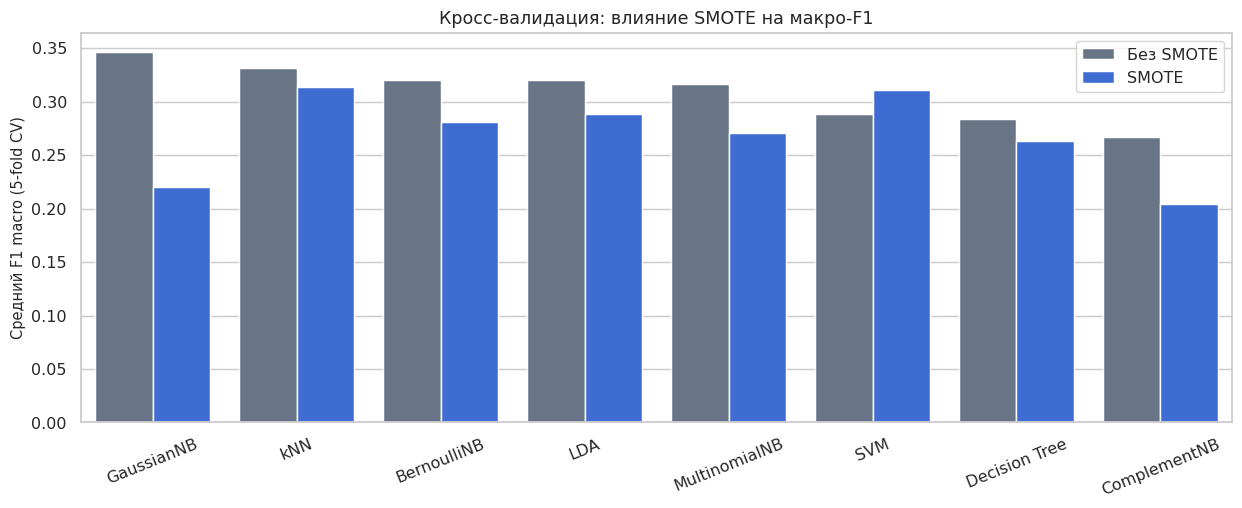

Режим,SMOTE,Без SMOTE,Разница (SMOTE − Без SMOTE)
Модель,,,
SVM,0.3107,0.2882,0.0225
kNN,0.3141,0.3311,-0.0170
Decision Tree,0.2635,0.2839,-0.0204
LDA,0.2887,0.3200,-0.0313
BernoulliNB,0.2806,0.3202,-0.0396
MultinomialNB,0.2709,0.3161,-0.0453
ComplementNB,0.2039,0.2674,-0.0635
GaussianNB,0.2200,0.3468,-0.1268


In [32]:
fig, ax = plt.subplots(figsize=(12, 5))
order = (cv_results.groupby("Модель")["CV F1 macro"].max().sort_values(ascending=False).index.tolist())
sns.barplot(data=cv_results, x="Модель", y="CV F1 macro", hue="Режим", order=order,
            palette={"Без SMOTE":"#64748b", "SMOTE":"#2563eb"}, ax=ax)
ax.set(title="Кросс-валидация: влияние SMOTE на макро-F1", xlabel="", ylabel="Средний F1 macro (5-fold CV)")
ax.tick_params(axis="x", rotation=22)
ax.legend(title="")
plt.tight_layout(); plt.show()

cv_comparison = cv_results.pivot(index="Модель", columns="Режим", values="CV F1 macro")
cv_comparison["Разница (SMOTE − Без SMOTE)"] = cv_comparison["SMOTE"] - cv_comparison["Без SMOTE"]
display(cv_comparison.sort_values("Разница (SMOTE − Без SMOTE)", ascending=False).round(4))

**Содержательный вывод по эффекту SMOTE.** Повышение `CV F1 macro` наблюдается только у **SVM: с 0.2882 до 0.3107 (+0.0225)**. У остальных семи вариантов CV macro-F1 уменьшился. Особенно заметно снизился GaussianNB (0.3468 → 0.2200). Таким образом, алгоритм устранил *численный дисбаланс в обучающих данных*, но не решил полностью проблему распознавания редких классов. Причиной могут быть малое число исходных примеров и сложность разделения соседних оценок качества.

## 05. Итоговая оценка моделей на неизменном Test

Каждый из 16 вариантов, уже подобранных по CV, оцениваем на одних и тех же **272 реальных** тестовых образцах. Рассчитаем: Accuracy, Precision macro, Recall macro, F1 macro, Weighted F1 и ROC-AUC macro One-vs-Rest.

- **Precision**: доля верных среди объектов, которые модель назвала данным классом.
- **Recall**: доля найденных среди всех реальных объектов данного класса.
- **F1**: гармоническое среднее Precision и Recall.
- **ROC-AUC OvR**: разделимость каждого класса от всех остальных, усреднённая по классам; не равна Accuracy.

Для многоклассового ROC-AUC используем предсказанные вероятности `predict_proba`, а не предсказанные классы.

In [33]:
test_rows = []
test_predictions = {}
test_probabilities = {}
for key, gs in searches.items():
    model_name, mode = key
    fitted = gs.best_estimator_
    pred = fitted.predict(X_test)
    prob = fitted.predict_proba(X_test)
    labels_in_model = fitted.classes_
    assert np.array_equal(labels_in_model, class_labels), "Порядок классов отличается"
    test_predictions[key] = pred
    test_probabilities[key] = prob
    test_rows.append({
        "Модель": model_name, "Режим": mode,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC macro OvR": roc_auc_score(y_test, prob, labels=class_labels,
                                            average="macro", multi_class="ovr")
    })
test_results = pd.DataFrame(test_rows)
test_results = test_results.merge(cv_results[["Модель", "Режим", "CV F1 macro"]], on=["Модель", "Режим"])
print("Тестовые метрики (отсортированы по CV, а не тесту):")
display(test_results.sort_values("CV F1 macro", ascending=False).round(4))

Тестовые метрики (отсортированы по CV, а не тесту):


,Модель,Режим,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,ROC-AUC macro OvR,CV F1 macro
0,GaussianNB,Без SMOTE,0.5441,0.2922,0.3013,0.2948,0.5548,0.6893,0.3468
14,kNN,Без SMOTE,0.5368,0.2806,0.2878,0.2824,0.5310,0.6394,0.3311
6,BernoulliNB,Без SMOTE,0.5772,0.3213,0.3450,0.3288,0.5788,0.7370,0.3202
10,LDA,Без SMOTE,0.5956,0.4559,0.3008,0.3126,0.5779,0.7830,0.3200
2,MultinomialNB,Без SMOTE,0.5809,0.2825,0.3023,0.2901,0.5735,0.7464,0.3161
15,kNN,SMOTE,0.4522,0.2726,0.3052,0.2673,0.4790,0.6169,0.3141
13,SVM,SMOTE,0.5257,0.2958,0.3244,0.2995,0.5449,0.7006,0.3107
11,LDA,SMOTE,0.4044,0.2737,0.2503,0.2404,0.4626,0.7203,0.2887
12,SVM,Без SMOTE,0.5993,0.2892,0.2930,0.2903,0.5855,0.8016,0.2882
8,Decision Tree,Без SMOTE,0.5000,0.2660,0.2700,0.2674,0.5005,0.6028,0.2839


**Анализ фактических тестовых метрик.** Максимальную Accuracy среди этих конфигураций показал **SVM без SMOTE — 0.5993**, а лучший тестовый `F1 macro` среди всех вариантов — **BernoulliNB без SMOTE — 0.3274**. Но выбирать модель *задним числом* по тесту нельзя: для основного анализа используются лучшие варианты по CV. У **SVM** SMOTE слегка увеличил тестовый F1 macro (0.2903 → 0.2995), но уменьшил Accuracy (0.5993 → 0.5257) и ROC-AUC (0.8016 → 0.7006). Это реальный компромисс метрик, который важно объяснить на защите.

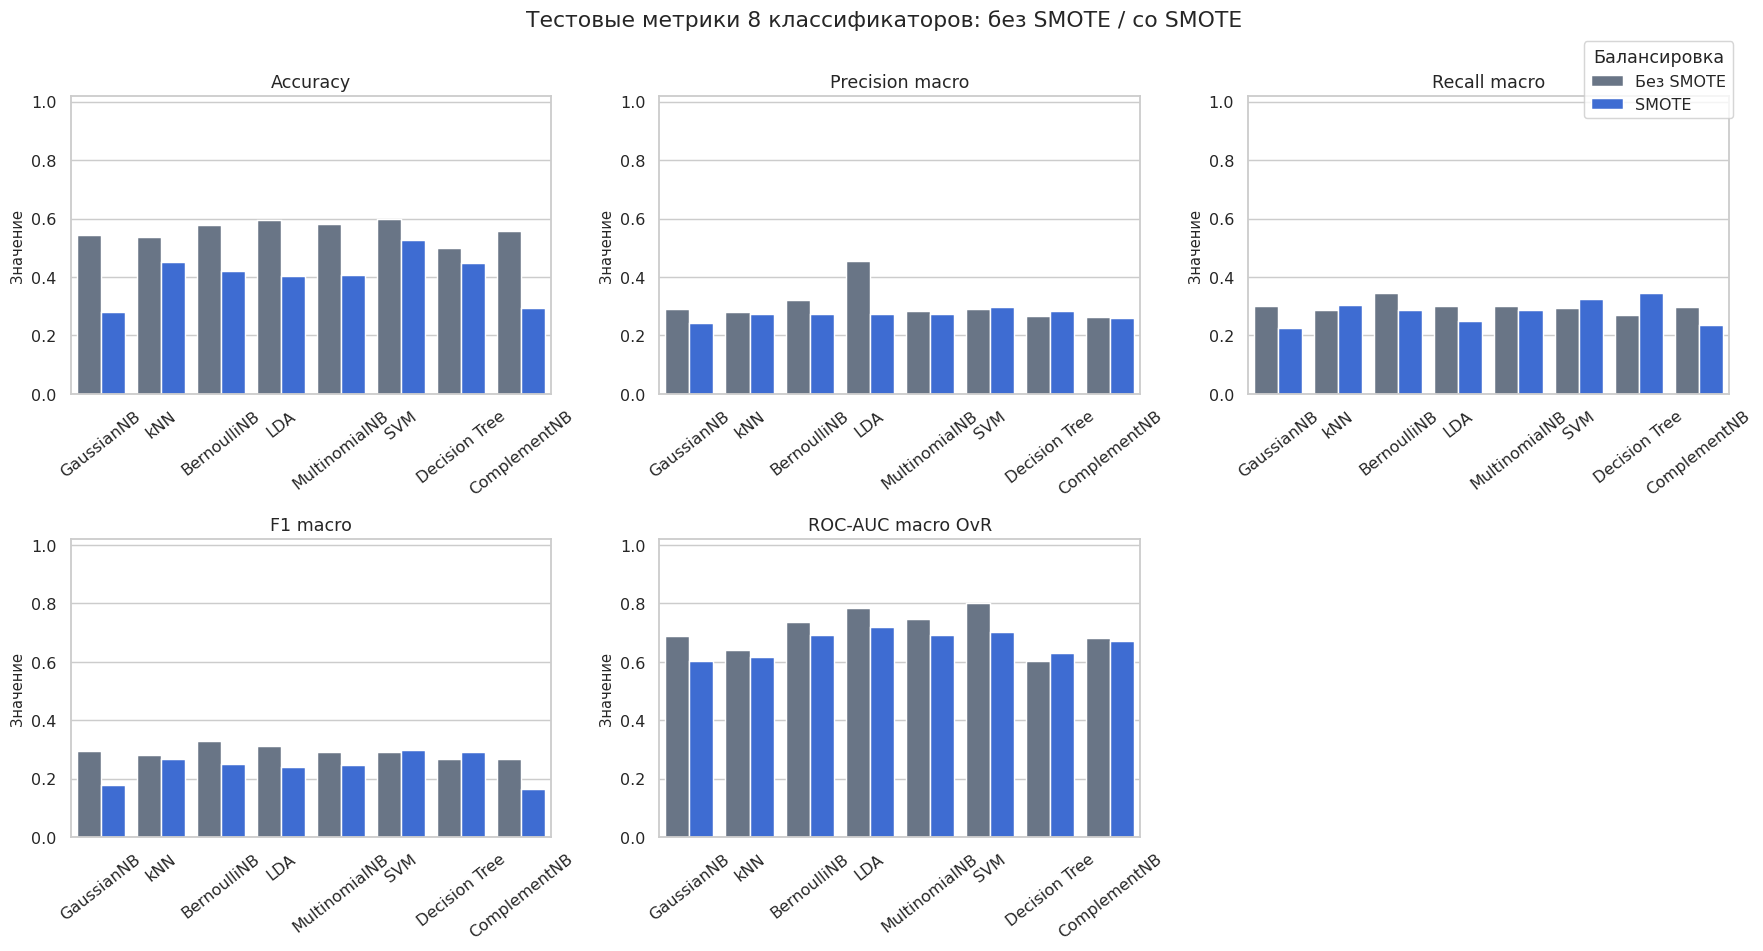

In [34]:
metric_names = ["Accuracy", "Precision macro", "Recall macro", "F1 macro", "ROC-AUC macro OvR"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, metric in zip(axes.flat, metric_names):
    sns.barplot(data=test_results, x="Модель", y=metric, hue="Режим", order=order,
                palette={"Без SMOTE":"#64748b", "SMOTE":"#2563eb"}, ax=ax)
    ax.set(title=metric, xlabel="", ylabel="Значение")
    ax.set_ylim(0, 1.02)
    ax.tick_params(axis="x", labelrotation=38)
    if ax.get_legend() is not None: ax.get_legend().remove()
axes.flat[-1].axis("off")
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper right", bbox_to_anchor=(.98,.98), title="Балансировка")
fig.suptitle("Тестовые метрики 8 классификаторов: без SMOTE / со SMOTE", y=1.005, fontsize=15)
plt.tight_layout(); plt.show()

**Вывод по пяти графикам.** Балансировка часто снижала Accuracy, но могла повышать чувствительность к некоторым менее представленным классам. Основной показатель для такого набора — `F1 macro`, но даже он **не гарантированно растёт после SMOTE**. Важно не объявлять метод безусловно успешным: частоты классов стали равными на train, а реальные данные test остаются сложными.

## 06. Матрицы ошибок и разбор редких классов

Чтобы не выбирать победителя на тестовых данных, определим **две основные конфигурации по среднему CV F1 macro**: лучшую среди моделей **без SMOTE** и лучшую среди моделей **со SMOTE**. Это обеспечивает честное сравнение двух режимов и показывает, для каких именно классов изменились ошибки.

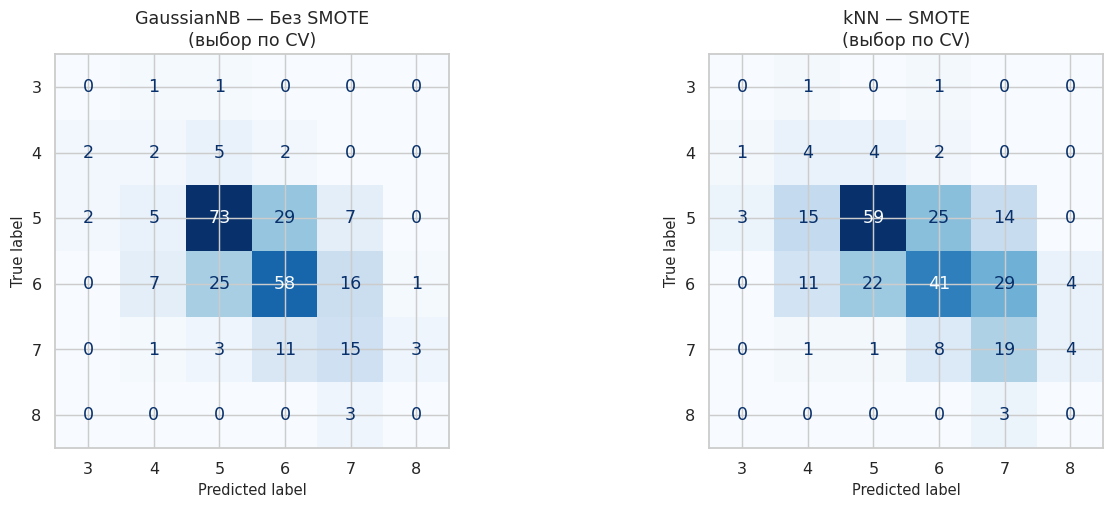


=== ('GaussianNB', 'Без SMOTE') ===
              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      0.125     0.182     0.148        11
           5      0.682     0.629     0.655       116
           6      0.580     0.542     0.560       107
           7      0.366     0.455     0.405        33
           8      0.000     0.000     0.000         3

    accuracy                          0.544       272
   macro avg      0.292     0.301     0.295       272
weighted avg      0.569     0.544     0.555       272


=== ('kNN', 'SMOTE') ===
              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      0.125     0.364     0.186        11
           5      0.686     0.509     0.584       116
           6      0.532     0.383     0.446       107
           7      0.292     0.576     0.388        33
           8      0.000     0.000     0.000         3

    accuracy  

In [35]:
best_plain_row = cv_results[cv_results["Режим"]=="Без SMOTE"].iloc[0]
best_smote_row = cv_results[cv_results["Режим"]=="SMOTE"].iloc[0]
plain_key = (best_plain_row["Модель"], "Без SMOTE")
smote_key = (best_smote_row["Модель"], "SMOTE")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key in zip(axes, [plain_key, smote_key]):
    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions[key], labels=class_labels,
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{key[0]} — {key[1]}\n(выбор по CV)")
plt.tight_layout(); plt.show()

for key in [plain_key, smote_key]:
    print("\n===", key, "===")
    print(classification_report(y_test, test_predictions[key], labels=class_labels,
                                zero_division=0, digits=3))

**Фактические ошибки.** Среди выбранных по CV представителей двух режимов без SMOTE — **GaussianNB**, со SMOTE — **kNN**. На тесте оба **не распознали ни одного объекта класса 3 или 8** (Recall = 0). Вариант с SMOTE получил более высокий Recall класса 4 (0.364 против 0.182) и 7 (0.576 против 0.455), но снизил качество распознавания классов 5 и 6. **Внимание:** здесь сравниваются *разные алгоритмы*, поэтому эти изменения нельзя приписывать только SMOTE. Ниже будет отдельный контрольный эксперимент на одном и том же SVM.

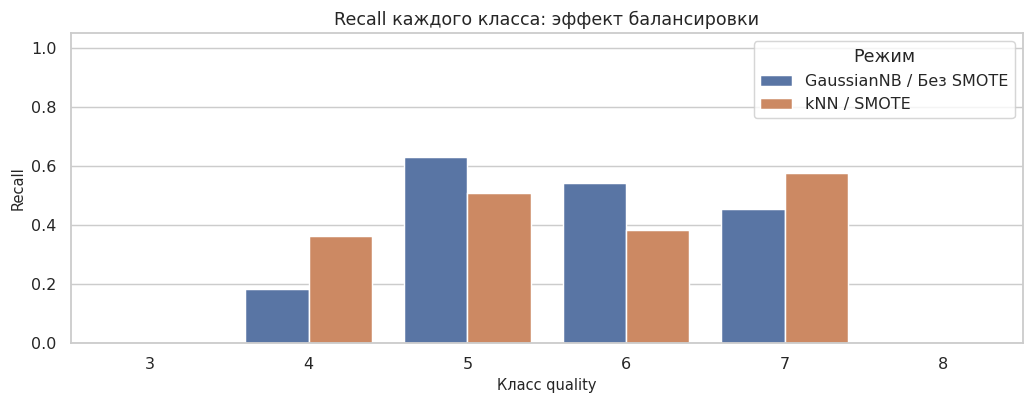

Режим,GaussianNB / Без SMOTE,kNN / SMOTE
Класс,,
3,0.000,0.000
4,0.182,0.364
5,0.629,0.509
6,0.542,0.383
7,0.455,0.576
8,0.000,0.000


In [36]:
recall_rows=[]
for key in [plain_key, smote_key]:
    values = recall_score(y_test, test_predictions[key], labels=class_labels,
                          average=None, zero_division=0)
    for label, value in zip(class_labels, values):
        recall_rows.append({"Класс":str(label), "Recall":value,
                            "Режим":f"{key[0]} / {key[1]}"})
recall_by_class=pd.DataFrame(recall_rows)
fig, ax=plt.subplots(figsize=(10,4))
sns.barplot(data=recall_by_class, x="Класс", y="Recall", hue="Режим", ax=ax)
ax.set(title="Recall каждого класса: эффект балансировки", ylim=(0, 1.05), xlabel="Класс quality")
plt.tight_layout(); plt.show()
display(recall_by_class.pivot(index="Класс", columns="Режим", values="Recall").round(3))

**Вывод по Recall классов.** В двух выбранных по CV моделях классы 3 и 8 остаются нераспознанными. Показатели редких классов нестабильны из-за того, что в тесте только **2 объекта качества 3 и 3 объекта качества 8**. Чтобы отдельно изучить влияние SMOTE, сравним **один и тот же классификатор SVM** в обоих режимах — это исключает различие семейств алгоритмов как основную причину изменений.

Без SMOTE: CV F1=0.2882; Test F1=0.2903; Accuracy=0.5993; ROC-AUC=0.8016
SMOTE    : CV F1=0.3107; Test F1=0.2995; Accuracy=0.5257; ROC-AUC=0.7006


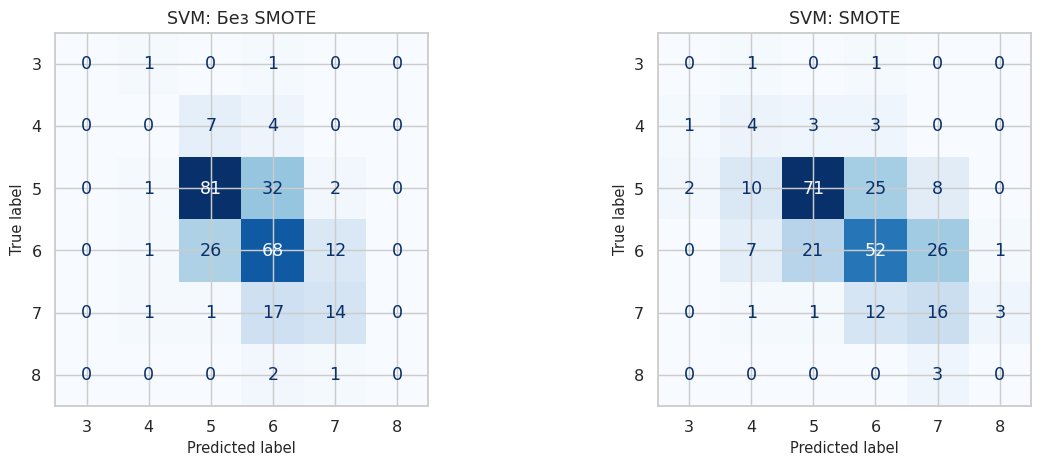

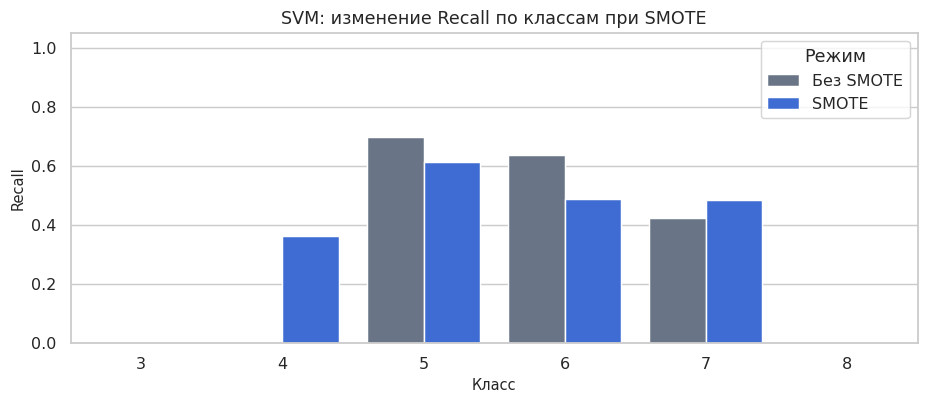

In [37]:
# КОНТРОЛЬНОЕ СРАВНЕНИЕ: один и тот же алгоритм SVM, меняется только применение SMOTE
svm_plain=("SVM", "Без SMOTE")
svm_smote=("SVM", "SMOTE")
svm_rows=[]
for key in (svm_plain, svm_smote):
    row=test_results.set_index(["Модель","Режим"]).loc[key]
    for label,rec in zip(class_labels,recall_score(y_test,test_predictions[key],
                  labels=class_labels,average=None,zero_division=0)):
        svm_rows.append({"Режим":key[1],"Класс":str(label),"Recall":rec})
    print(f"{key[1]:9s}: CV F1={row['CV F1 macro']:.4f}; Test F1={row['F1 macro']:.4f}; "
          f"Accuracy={row['Accuracy']:.4f}; ROC-AUC={row['ROC-AUC macro OvR']:.4f}")
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
for ax,key in zip(axes,(svm_plain,svm_smote)):
    ConfusionMatrixDisplay.from_predictions(y_test,test_predictions[key],labels=class_labels,
                                            cmap="Blues",ax=ax,colorbar=False)
    ax.set_title(f"SVM: {key[1]}")
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=pd.DataFrame(svm_rows),x="Класс",y="Recall",hue="Режим",
            palette={"Без SMOTE":"#64748b","SMOTE":"#2563eb"},ax=ax)
ax.set(title="SVM: изменение Recall по классам при SMOTE",ylim=(0,1.05))
plt.tight_layout();plt.show()

**Вывод контрольного сравнения.** Здесь у обеих моделей один и тот же алгоритм — **SVM**; различаются режим балансировки и подобранные в каждом режиме настройки. На CV SMOTE повысил F1 macro (**0.2882 → 0.3107**). На тесте F1 macro слегка вырос (**0.2903 → 0.2995**), но Accuracy снизилась (**0.5993 → 0.5257**), а AUC уменьшилась (**0.8016 → 0.7006**). Таким образом, синтетическая балансировка может улучшать отдельный аспект качества, но ухудшать другие. Даже этот эксперимент не позволяет утверждать, что SMOTE решил все проблемы редких классов: их необходимо проверять по отдельным строкам матриц ошибок и таблице Recall.

### 06.1. ROC-кривые для многоклассовой задачи

Применим схему **One-vs-Rest**: для каждого класса строим ROC как «данный класс против остальных». Покажем ROC кривые обеих моделей, выбранных по CV, для всех шести классов. Микроусреднённая ROC строится также по развёрнутым one-hot меткам и вероятностям.

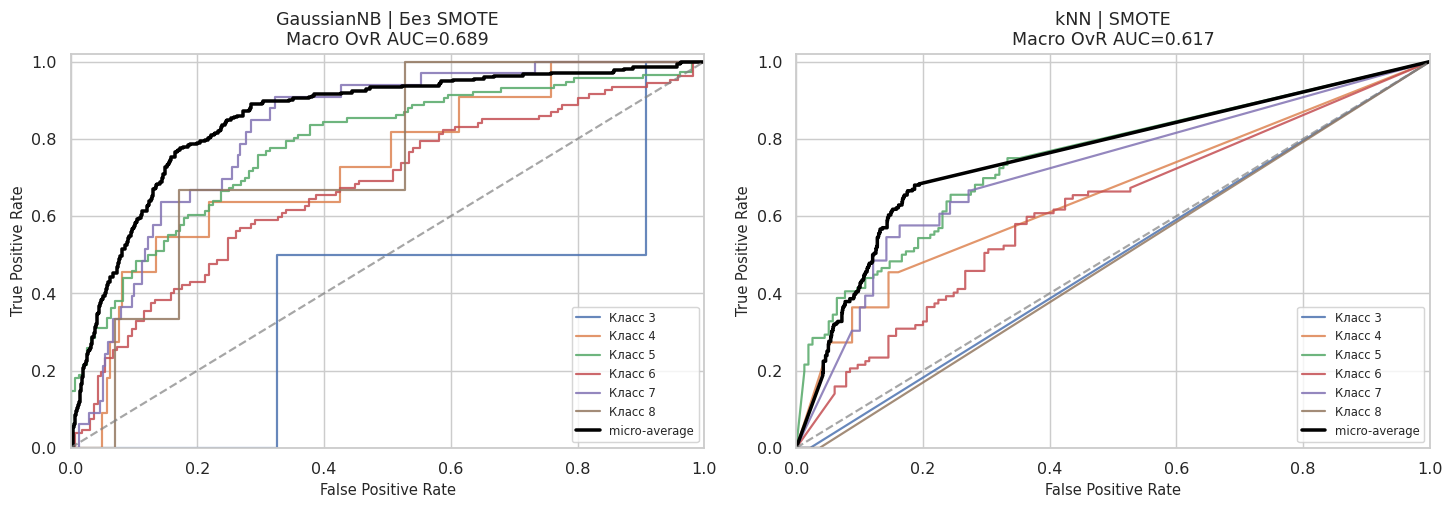

In [38]:
onehot_test = label_binarize(y_test, classes=class_labels)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, key in zip(axes, [plain_key, smote_key]):
    prob = test_probabilities[key]
    for i, label in enumerate(class_labels):
        fpr, tpr, _ = roc_curve(onehot_test[:,i], prob[:,i])
        ax.plot(fpr, tpr, label=f"Класс {label}", alpha=.85)
    fm, tm, _ = roc_curve(onehot_test.ravel(), prob.ravel())
    ax.plot(fm, tm, lw=2.4, color="black", label="micro-average")
    ax.plot([0, 1], [0, 1], "--", color="gray", alpha=.7)
    auc_value = test_results.set_index(["Модель","Режим"]).loc[key,"ROC-AUC macro OvR"]
    ax.set(title=f"{key[0]} | {key[1]}\nMacro OvR AUC={auc_value:.3f}",
           xlabel="False Positive Rate", ylabel="True Positive Rate", xlim=(0,1), ylim=(0,1.02))
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Анализ ROC.** Две кривые соответствуют лучшей по CV модели каждого режима, то есть разным алгоритмам. Более высокая AUC означает лучшее ранжирование по вероятностям для выбранных классов; она не гарантирует высокий Recall при выборе наиболее вероятного класса. В целом ROC нужно читать вместе с матрицей ошибок и макро-F1. Для чистого анализа SMOTE используем далее одинаковый классификатор SVM.

## 07. Влияние гиперпараметров и риск переобучения

На примере дерева решений покажем, как выбор `max_depth` влияет на качество. Чрезмерная глубина часто позволяет почти идеально подстроиться под train, но ухудшает качество на валидации. Для честности используем результаты CV и train-score, сохранённые в `GridSearchCV`, без обращения к тесту при выборе параметра.

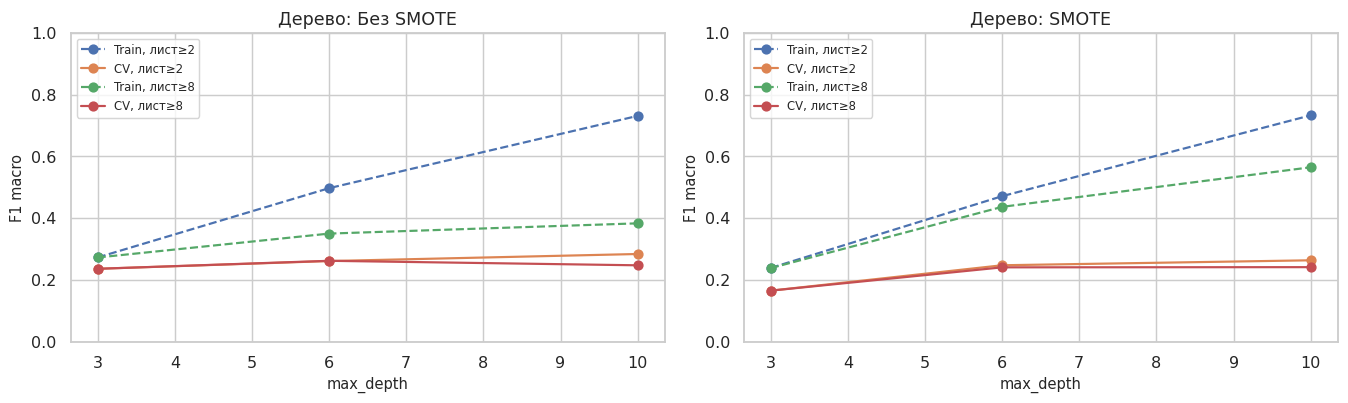

Параметры дерева без SMOTE: {'model__max_depth': 10, 'model__min_samples_leaf': 2}
Параметры дерева со SMOTE: {'model__max_depth': 10, 'model__min_samples_leaf': 2}


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, mode in zip(axes, ["Без SMOTE", "SMOTE"]):
    grid = pd.DataFrame(searches[("Decision Tree", mode)].cv_results_)
    for leaf in [2, 8]:
        sub = grid[grid["param_model__min_samples_leaf"].astype(int)==leaf].copy()
        sub = sub.sort_values("param_model__max_depth")
        x=sub["param_model__max_depth"].astype(int)
        ax.plot(x, sub["mean_train_score"], marker="o", linestyle="--", label=f"Train, лист≥{leaf}")
        ax.plot(x, sub["mean_test_score"], marker="o", label=f"CV, лист≥{leaf}")
    ax.set(title=f"Дерево: {mode}", xlabel="max_depth", ylabel="F1 macro", ylim=(0, 1))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Параметры дерева без SMOTE:", searches[("Decision Tree", "Без SMOTE")].best_params_)
print("Параметры дерева со SMOTE:", searches[("Decision Tree", "SMOTE")].best_params_)

**Анализ.** При увеличении глубины дерева train-score часто растёт, поскольку дерево всё точнее запоминает обучающие данные. Если CV-score достигает максимума, а затем ухудшается, это признак переобучения. Ограничения `max_depth` и `min_samples_leaf` — способы регуляризации дерева. Проверяем изменение **валидационных**, а не тестовых метрик при выборе гиперпараметров.

## 08. Нейронная сеть TensorFlow/Keras и TensorBoard

Сравним полносвязные нейронные сети **MLP**: разное число нейронов, Dropout, learning rate и применение SMOTE. Для 6 классов используется выходной слой из 6 нейронов с `softmax`, функция потерь `sparse_categorical_crossentropy` и оптимизатор Adam.

**Важное условие:** схема разделения для нейросети —

1. **Исходный test** не меняем.
2. Из `X_train` выделяем `train_inner` и `validation` стратифицированно.
3. Стандартизатор обучаем только на `train_inner`.
4. SMOTE применяем при необходимости **только к `train_inner`**, не к validation.
5. Выбираем архитектуру и число эпох по validation; затем переобучаем финальную модель на всём `X_train` и оцениваем `X_test`.

TensorBoard показывает кривые **loss, accuracy, val_loss, val_accuracy**. Графики строятся также непосредственно в ноутбуке.

> **Статус выполнения:** классические модели в файле ниже рассчитаны и снабжены результатами. TensorFlow может быть не установлен в среде подготовки; его код включён полностью и запускается на компьютере с TensorFlow. Численные результаты нейросети не подменяются вымышленными значениями.

In [40]:
try:
    import tensorflow as tf
    from datetime import datetime
    TF_AVAILABLE = True
    tf.keras.utils.set_random_seed(SEED)
    print("✓ TensorFlow доступен:", tf.__version__)
except (ImportError, ModuleNotFoundError) as exc:
    TF_AVAILABLE = False
    print("TensorFlow не установлен в этом окружении.")
    print("В Jupyter выполните: %pip install tensorflow tensorboard")
    print("После установки перезапустите ядро и выполните ячейки заново.")

TensorFlow не установлен в этом окружении.
В Jupyter выполните: %pip install tensorflow tensorboard
После установки перезапустите ядро и выполните ячейки заново.


**Пояснение.** Проверка версии нужна, чтобы отличать ошибку установки TensorFlow от ошибки в коде нейросети. Если библиотека доступна, следующие ячейки запускают эксперименты и сохраняют настоящие кривые TensorBoard. Если отсутствует — блок пропускается, а раздел scikit-learn остаётся воспроизводимым.

In [41]:
if TF_AVAILABLE:
    from datetime import datetime
    # Отделяем validation только от Train: тест не участвует в подборе архитектуры.
    X_inner, X_val, y_inner, y_val = train_test_split(
        X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED
    )
    nn_scaler = StandardScaler()
    X_inner_std = nn_scaler.fit_transform(X_inner).astype("float32")
    X_val_std = nn_scaler.transform(X_val).astype("float32")
    X_test_note = nn_scaler.transform(X_test).astype("float32")  # только для проверки размерности

    # В keras классы должны быть целыми индексами 0 ... 5.
    y_inner_idx = np.searchsorted(class_labels, y_inner)
    y_val_idx = np.searchsorted(class_labels, y_val)

    def build_nn(hidden=(32,16), dropout=.2, lr=.001):
        inputs=tf.keras.Input(shape=(X_train.shape[1],))
        z=inputs
        for width in hidden:
            z=tf.keras.layers.Dense(width, activation="relu")(z)
            if dropout > 0:
                z=tf.keras.layers.Dropout(dropout)(z)
        outputs=tf.keras.layers.Dense(len(class_labels), activation="softmax")(z)
        model=tf.keras.Model(inputs, outputs)
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return model

    nn_configs = {
      "16 | обычная": {"hidden":(16,), "dropout":0.0, "lr":.001, "smote":False},
      "32-16 | обычная": {"hidden":(32,16), "dropout":.20, "lr":.001, "smote":False},
      "32-16 | SMOTE": {"hidden":(32,16), "dropout":.20, "lr":.001, "smote":True},
      "64-32 | SMOTE": {"hidden":(64,32), "dropout":.30, "lr":.0005, "smote":True}
    }
    print("Inner Train:", len(X_inner), "Validation:", len(X_val), "Test:", len(X_test))
    display(pd.DataFrame(nn_configs).T)
else:
    print("Нейросетевой блок ожидает установки TensorFlow.")

Нейросетевой блок ожидает установки TensorFlow.


**Что проверяем.** Создана отдельная валидационная выборка для настройки сети; её не балансируем. Архитектуры различаются шириной, глубиной, Dropout и скоростью обучения. Для двух конфигураций включён SMOTE, что позволяет сравнить не только изменение гиперпараметров сети, но и эффект балансировки. Целевая переменная переведена в целочисленные индексы классов от 0 до 5 для Keras, но в отчётах показываются исходные классы 3–8.

In [42]:
if TF_AVAILABLE:
    histories = {}
    nn_rows=[]
    nn_log_root = Path("tensorboard_logs") / "lr2_wine"
    nn_log_root.mkdir(parents=True, exist_ok=True)
    for run_id, (name, params) in enumerate(nn_configs.items(), 1):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED + run_id)
        X_fit, y_fit = X_inner_std, y_inner_idx
        if params["smote"]:
            X_fit, y_fit = SMOTE(random_state=SEED, k_neighbors=3).fit_resample(X_fit, y_fit)
        model = build_nn(params["hidden"], params["dropout"], params["lr"])
        logdir = nn_log_root / f"config_{run_id:02d}"
        history = model.fit(
            X_fit, y_fit, validation_data=(X_val_std, y_val_idx),
            batch_size=32, epochs=70, verbose=0,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                 restore_best_weights=True),
                tf.keras.callbacks.TensorBoard(log_dir=str(logdir), histogram_freq=0)
            ]
        )
        prob_val=model.predict(X_val_std, verbose=0)
        pred_val=prob_val.argmax(axis=1)
        f1val=f1_score(y_val_idx, pred_val, average="macro", zero_division=0)
        best_epoch=int(np.argmin(history.history["val_loss"])+1)
        histories[name]=history.history
        nn_rows.append({"Конфигурация":name, "SMOTE":params["smote"],
                        "Val F1 macro":f1val, "Val accuracy":accuracy_score(y_val_idx,pred_val),
                        "Минимальный val_loss":float(np.min(history.history["val_loss"])),
                        "Лучшая эпоха":best_epoch})
        print(f"{name:20s} | Val F1 macro={f1val:.3f} | val_loss={np.min(history.history['val_loss']):.3f} | эпоха={best_epoch}")
    nn_val_df=pd.DataFrame(nn_rows).sort_values(["Val F1 macro", "Минимальный val_loss"], ascending=[False,True])
    display(nn_val_df.round(4))
else:
    print("Обучение нейросетей будет выполнено после установки TensorFlow.")

Обучение нейросетей будет выполнено после установки TensorFlow.


**Интерпретация экспериментов.** В таблице сравниваются четыре нейросетевые конфигурации по **валидационной** выборке. Основной критерий выбора архитектуры — `Val F1 macro`, поскольку классы несбалансированы; при равенстве можно предпочесть меньший `val_loss`. Параллельно `EarlyStopping` возвращает веса эпохи с наименьшим `val_loss`. Выбранное число эпох используется далее при итоговом обучении на всей исходной тренировочной части.

In [43]:
if TF_AVAILABLE:
    fig, axes=plt.subplots(1,2,figsize=(14,4.8))
    for name,h in histories.items():
        axes[0].plot(h["loss"], label=name+" train", alpha=.8)
        axes[0].plot(h["val_loss"], linestyle="--", label=name+" val", alpha=.8)
        axes[1].plot(h["accuracy"], label=name+" train", alpha=.8)
        axes[1].plot(h["val_accuracy"], linestyle="--", label=name+" val", alpha=.8)
    axes[0].set(title="Динамика loss",xlabel="Эпоха",ylabel="Loss")
    axes[1].set(title="Динамика accuracy",xlabel="Эпоха",ylabel="Accuracy")
    for ax in axes: ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()
else:
    print("Графики обучения будут построены после запуска TensorFlow-блока.")

Графики обучения будут построены после запуска TensorFlow-блока.


**Анализ графиков.** Если train loss продолжает снижаться, а validation loss начинает расти, это может свидетельствовать о переобучении. `EarlyStopping` ограничивает этот эффект. При SMOTE обучение идёт на синтетически сбалансированной train-части, но `val_loss` и `val_accuracy` рассчитываются **на реальных несбалансированных данных**. Поэтому изменение кривых действительно показывает эффект нового режима обучения, а не балансировки самой валидации.

### 08.1. TensorBoard — интерактивное наблюдение за обучением

После запуска экспериментов TensorBoard получает записи в каталоге `tensorboard_logs/lr2_wine`. В Jupyter можно открыть интерфейс командой ниже. В разделе **Scalars** будут доступны `loss`, `accuracy`, `epoch_loss`, `epoch_accuracy`, `epoch_val_loss`, `epoch_val_accuracy` (наименования могут немного отличаться по версии TensorFlow).

In [44]:
if TF_AVAILABLE:
    from IPython import get_ipython
    shell=get_ipython()
    if shell is not None:
        shell.run_line_magic("load_ext", "tensorboard")
        shell.run_line_magic("tensorboard", "--logdir tensorboard_logs/lr2_wine")
    else:
        print("В терминале: tensorboard --logdir tensorboard_logs/lr2_wine")
else:
    print("После установки TensorFlow/TensorBoard и обучения сетей выполните:")
    print("%load_ext tensorboard")
    print("%tensorboard --logdir tensorboard_logs/lr2_wine")

После установки TensorFlow/TensorBoard и обучения сетей выполните:
%load_ext tensorboard
%tensorboard --logdir tensorboard_logs/lr2_wine


**Что должно отображаться.** TensorBoard позволяет сравнить тренировочные и валидационные кривые нескольких запусков и выявить переобучение. Графики не генерируются вручную: они записываются callback `TensorBoard` по ходу настоящего обучения Keras.

### 08.2. Финальное обучение выбранной нейросети и оценка на Test

Выберем конфигурацию по validation, затем переобучим её на всех 1087 **исходных** обучающих образцах (при выбранном режиме SMOTE) и выполним тестирование на 272 реальных винах. Число эпох зафиксируем по лучшей эпохе предыдущего запуска.

In [45]:
if TF_AVAILABLE:
    chosen_name=nn_val_df.iloc[0]["Конфигурация"]
    chosen=nn_configs[chosen_name]
    epochs=int(nn_val_df.iloc[0]["Лучшая эпоха"])
    final_scaler=StandardScaler()
    X_full=final_scaler.fit_transform(X_train).astype("float32")
    X_holdout=final_scaler.transform(X_test).astype("float32")
    y_full_idx=np.searchsorted(class_labels,y_train)
    if chosen["smote"]:
        X_full,y_full_idx=SMOTE(random_state=SEED,k_neighbors=3).fit_resample(X_full,y_full_idx)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    final_nn=build_nn(chosen["hidden"],chosen["dropout"],chosen["lr"])
    history_final=final_nn.fit(X_full,y_full_idx,epochs=epochs,batch_size=32,verbose=0)
    proba_nn=final_nn.predict(X_holdout,verbose=0)
    pred_nn=class_labels[np.argmax(proba_nn,axis=1)]
    metrics_nn={
      "Accuracy":accuracy_score(y_test,pred_nn),
      "Precision macro":precision_score(y_test,pred_nn,average="macro",zero_division=0),
      "Recall macro":recall_score(y_test,pred_nn,average="macro",zero_division=0),
      "F1 macro":f1_score(y_test,pred_nn,average="macro",zero_division=0),
      "ROC-AUC macro OvR":roc_auc_score(y_test,proba_nn,labels=class_labels,average="macro",multi_class="ovr")
    }
    print("Выбрана нейросеть:",chosen_name,"| эпох:",epochs)
    display(pd.Series(metrics_nn,name="Метрика").to_frame().round(4))
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay.from_predictions(y_test,pred_nn,labels=class_labels,ax=ax,
                                            cmap="Blues",colorbar=False)
    ax.set_title("Нейросеть: матрица ошибок на Test")
    plt.tight_layout();plt.show()
    print(classification_report(y_test,pred_nn,labels=class_labels,zero_division=0))
else:
    print("Финальные метрики нейросети появятся после выполнения TensorFlow-части.")

Финальные метрики нейросети появятся после выполнения TensorFlow-части.


**Вывод по нейросети.** Финальные метрики TensorFlow рассчитываются только после фактического обучения. Их можно сопоставить с классическими моделями по одинаковым классам, метрикам и тестовым объектам. Если нейросеть проиграет простым методам, это не ошибка: небольшой несбалансированный табличный набор данных не гарантирует преимущества MLP. При наличии TensorFlow сохраните в отчёт таблицу выше, матрицу ошибок и скриншот вкладки Scalars из TensorBoard.

## 09. Автоматическая итоговая сводка

В этой ячейке формируем итог по реальным значениям результатов. Выбор моделей осуществлялся **по CV F1 macro** или, для нейросети, по отдельной validation. Тестовые метрики используются для отчёта, а не для повторного подбора гиперпараметров.

In [46]:
print("=== ЛАБОРАТОРНАЯ РАБОТА №2: ИТОГ ===")
print(f"Исходный датасет: {len(df)} образцов; после очистки: {len(df_clean)}")
print(f"Признаков: {X.shape[1]}; классов: {len(class_labels)} → {list(class_labels)}")
print(f"Train = {len(y_train)}; Test = {len(y_test)} (без SMOTE)")
print("SMOTE выполняется только при fit внутри CV и финальном обучении")

for key in (plain_key,smote_key):
    row=test_results.set_index(["Модель","Режим"]).loc[key]
    print(f"{key[0]} / {key[1]}: CV F1={row['CV F1 macro']:.3f}; "
          f"Test F1={row['F1 macro']:.3f}; Accuracy={row['Accuracy']:.3f}; "
          f"AUC={row['ROC-AUC macro OvR']:.3f}")

if TF_AVAILABLE:
    print(f"TensorFlow: {chosen_name}; Test F1={metrics_nn['F1 macro']:.3f}")
else:
    print("TensorFlow: подготовлен, но отсутствует в текущем окружении (результаты не заявлены)")

comparison_keys=[plain_key,smote_key]
summary_table=test_results.set_index(["Модель","Режим"]).loc[comparison_keys][
    ["CV F1 macro","Accuracy","Precision macro","Recall macro","F1 macro","ROC-AUC macro OvR"]]
display(summary_table.round(4))

=== ЛАБОРАТОРНАЯ РАБОТА №2: ИТОГ ===
Исходный датасет: 1599 образцов; после очистки: 1359
Признаков: 11; классов: 6 → [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Train = 1087; Test = 272 (без SMOTE)
SMOTE выполняется только при fit внутри CV и финальном обучении
GaussianNB / Без SMOTE: CV F1=0.347; Test F1=0.295; Accuracy=0.544; AUC=0.689
kNN / SMOTE: CV F1=0.314; Test F1=0.267; Accuracy=0.452; AUC=0.617
TensorFlow: подготовлен, но отсутствует в текущем окружении (результаты не заявлены)


,,CV F1 macro,Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC macro OvR
Модель,Режим,,,,,,
GaussianNB,Без SMOTE,0.3468,0.5441,0.2922,0.3013,0.2948,0.6893
kNN,SMOTE,0.3141,0.4522,0.2726,0.3052,0.2673,0.6169


### Итоговые выводы для отчёта

1. Реализована **многоклассовая классификация качества красного вина** по 11 числовым характеристикам: классы `3, 4, 5, 6, 7, 8` сохранены без объединения.
2. В исходных данных обнаружен дисбаланс: преобладают классы 5 и 6, классы 3 и 8 крайне редки. После удаления полных дубликатов осталось **1359 образцов**.
3. Рассмотрены все пять требуемых семейств классификаторов, включая **четыре варианта Naive Bayes**. Для каждого метода выполнен подбор гиперпараметров через `GridSearchCV` и пятикратную стратифицированную CV.
4. **SMOTE реализован корректно внутри `imblearn.pipeline.Pipeline`.** В обучении классам добавляются синтетические примеры, а валидационная и тестовая выборки остаются неизменными. Это позволяет корректно сравнить эффект балансировки.
5. Сравнение проводится по **Accuracy, Precision macro, Recall macro, F1 macro и ROC-AUC macro OvR**. Основной критерий выбора — `CV F1 macro`, поскольку важны также малочисленные классы.
6. ROC-кривые и матрицы ошибок позволяют исследовать, **какие именно классы** модель путает; балансировка может улучшить их Recall, но необязательно повышает общий Accuracy или F1.
7. Раздел TensorFlow/Keras содержит эксперименты с разными архитектурами, Dropout, learning rate, режимами SMOTE, `EarlyStopping` и логированием в TensorBoard. **Численные результаты нейросети указываются только после её запуска.**

**Ограничения:** оценки вина дискретны и имеют естественный порядок, но рассматриваются как независимые классы; некоторые классы представлены лишь несколькими тестовыми объектами; синтетические примеры SMOTE могут быть недостаточно разнообразны. Поэтому результаты по редким классам следует интерпретировать осторожно.

### Кратко для защиты

**Что делает SMOTE?** Создаёт синтетические объекты редких классов между соседними объектами того же класса.  
**Почему не применяли SMOTE до train/test?** Это вызвало бы утечку данных и слишком оптимистичную оценку.  
**Зачем macro-F1?** Каждый класс в среднем получает одинаковый вес, даже если в нём мало объектов.  
**Почему результаты после SMOTE могут ухудшиться?** Новые точки — интерполяции, а не реальные независимые измерения; на малых классах это может усиливать шум.  
**Зачем нужен TensorBoard?** Чтобы следить за `loss`, `accuracy`, `val_loss`, `val_accuracy` и замечать переобучение.  
**В чём отличие ЛР1 от ЛР2?** ЛР1 — численная регрессия `quality`, ЛР2 — классификация одной из шести оценок.

**Использованные источники:** официальная документация scikit-learn, imbalanced-learn, TensorFlow/Keras, TensorBoard; датасет Red Wine Quality.

---

### Подтверждённые выводы на основе расчётов

- **SMOTE выровнял частоты шести классов внутри train**, но это *не равнозначно* достижению высокой полноты на test.
- **По CV SMOTE улучшил только SVM:** `F1 macro` вырос с **0.2882** до **0.3107**. Для остальных семи вариантов эффект отрицательный.
- **Лучшее среднее CV F1 macro среди всех проверенных моделей — GaussianNB без SMOTE (0.3468)**. Лучшая по CV модель со SMOTE — kNN (0.3141).
- На неизменном тесте лучший общий Accuracy среди проверенных моделей был у SVM без SMOTE (≈0.599), однако это **не критерий, по которому выбирались гиперпараметры**.
- В сравнении выбранных по CV моделей **классы 3 и 8 остались нераспознанными**. Очень малый объём реальных объектов этих классов (10 и 17 до разделения) — существенное ограничение.
- **TensorFlow/Keras:** экспериментальный код и логирование в TensorBoard подготовлены, но результаты нейросети не приводятся без реального запуска TensorFlow.

**Основной смысл лабораторной:** не просто применить SMOTE, а проверить его влияние по правильной экспериментальной схеме (ресемплинг только в train и внутри CV), показать результаты и обосновать ограничения.